In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("../Data/raw/PS_log.csv")
# df= df.drop_duplicates(subset=['transaction_id', 'user_id', 'transaction_date',
                        # 'transaction_amount', 'merchant_id', 'merchant_category', 'is_fraud'],last=False)

# df.head(20)
# df.fillna(0, inplace=True)
df.head(50) 

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


In [ ]:
# #This code snippet creates a new column called "first_flag_mismatch" in the DataFrame df. The new column is created by checking two conditions: whether the value in the "prev_transactions" column is greater than 0 and whether the value in the "is_first_transaction" column is equal to 1. If both conditions are met, the value in the "first_flag_mismatch" column will be set to 1; otherwise, it will be set to 0. The resulting values are then converted to integers using the astype(int) method.
# df["first_flag_mismatch"] = ((df["prev_transactions"] > 0) & (df["is_first_transaction"] == 1)).astype(int)
# pd.crosstab(df["first_flag_mismatch"], df["is_fraud"], normalize="index")
# #This round the value to whole number and convert it to integer type.
# df["customer_age"] = df["customer_age"].round().astype(int)
# df["velocity_score"] = df["velocity_score"].round().astype(int)
# df[["hour_of_day", "num_items","customer_age","prev_transactions", "is_first_transaction","velocity_score","is_fraud"]].head(100)


In [14]:
# Group the DataFrame by "type" and calculate fraud statistics
fraud_by_type = (
    df.groupby("type")["isFraud"]
      .agg(
          transactions="size",
          fraud_transactions="sum",
          fraud_rate="mean"
      )
      .assign(fraud_rate_percent=lambda x: x["fraud_rate"] * 100)
      .sort_values("fraud_rate_percent", ascending=False)
)

fraud_by_type

,transactions,fraud_transactions,fraud_rate,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


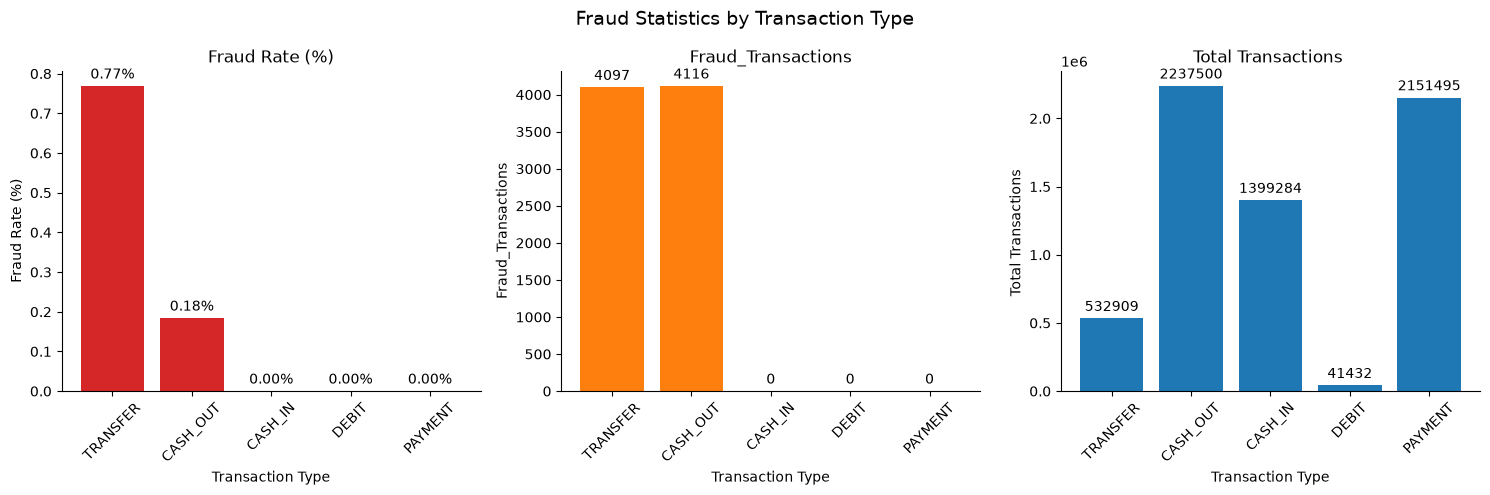

In [15]:
fig, ax=plt.subplots(1 , 3, figsize=(15, 5))

charts=[("fraud_rate_percent", "Fraud Rate (%)", "tab:red","{:.2f}%") ,
        ("fraud_transactions", "Fraud_Transactions","tab:orange","{:.0f}"),
        ("transactions", "Total Transactions ", "tab:blue","{:.0f}") ]

for ax, (column, title, color, fmt) in zip(ax, charts):
    bars=ax.bar(fraud_by_type.index, fraud_by_type[column], color=color)
    ax.bar_label(bars, labels=[fmt.format(v) for v in fraud_by_type[column]], padding=3)
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.set_xlabel("Transaction Type")
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle("Fraud Statistics by Transaction Type", fontsize=14)
plt.tight_layout()
plt.show()
   

In [16]:
# Calculate median values for specific columns, grouped by "isFraud"
print(df.groupby("isFraud")[["amount", "oldbalanceOrg", "newbalanceOrig"]].median())
frac_empty = (df["newbalanceOrig"] == 0).groupby(df["isFraud"]).mean()
print("\nShare of rows where the sender ends with a zero balance:\n", frac_empty)
# The code snippet calculates the fraction of rows in the DataFrame df where the "newbalanceOrig" column is equal to 0, grouped by the "isFraud" column. It uses a boolean condition (df["newbalanceOrig"] == 0) to create a boolean Series, which is then grouped by the "isFraud" column using the groupby() method. The mean() function is applied to calculate the average of the boolean values (True = 1, False = 0) for each group, resulting in the fraction of rows with a zero balance for both fraudulent and non-fraudulent transactions. The result is stored in the variable frac_empty and printed to the console.
frac_empty = (df["newbalanceOrig"] == 0).groupby(df["isFraud"]).mean()
print("\nShare of rows where the sender ends with a zero balance:\n", frac_empty)

            amount  oldbalanceOrg  newbalanceOrig
isFraud                                          
0         74684.72       14069.00             0.0
1        441423.44      438983.45             0.0

Share of rows where the sender ends with a zero balance:
 isFraud
0    0.566774
1    0.980519
Name: newbalanceOrig, dtype: float64

Share of rows where the sender ends with a zero balance:
 isFraud
0    0.566774
1    0.980519
Name: newbalanceOrig, dtype: float64
